# Next Day Wildfire Spread

Each sample is a 64 by 64 km patch at 1 km resolution. Twelve grids are inputs, and `FireMask` is the label: where fire is the next day. The fire masks use 1 for fire, 0 for no fire, and -1 for uncertain, usually clouds.

This notebook reads the first data file only. The loading code lives in `inspect_ndws.py` next to this notebook. It downloads that file into `data/ndws/` at the repo root the first time it runs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

from inspect_ndws import download_first_shard, feature_table, read_examples, sample_table

SAMPLE_COUNT = 20

shard = download_first_shard()
examples = read_examples(shard, SAMPLE_COUNT)
print(f"Read {len(examples)} samples from {shard.name}")

Using existing /Users/lokeshp/Projects/AIS_SkyAlert/skyalert/data/ndws/next_day_wildfire_spread_eval_00.tfrecord
Read 20 samples from next_day_wildfire_spread_eval_00.tfrecord


## Features

One row per grid. `min`, `max`, and `mean` are over every pixel in the samples loaded above.

In [2]:
features = feature_table(examples)
features

,feature,role,shape,meaning,min,max,mean
0,elevation,input,64x64,"Elevation, meters",19.0000,3110.0000,791.2781
1,th,input,64x64,"Wind direction, degrees clockwise from north",14.0215,313.2712,177.1435
2,vs,input,64x64,"Wind speed, meters per second",1.6848,9.7736,4.2411
3,tmmn,input,64x64,"Minimum temperature, kelvin",265.9525,294.7608,281.5869
4,tmmx,input,64x64,"Maximum temperature, kelvin",277.0347,312.9289,297.2613
5,sph,input,64x64,Specific humidity,0.0025,0.0091,0.0057
6,pr,input,64x64,"Precipitation, millimeters",-0.0256,35.7356,2.3434
7,pdsi,input,64x64,Palmer Drought Severity Index,-4.8025,4.7365,-0.1834
8,NDVI,input,64x64,"Vegetation index, stored scaled rather than -1...",-5968.0000,9765.0000,4813.8008
9,population,input,64x64,Population density,0.0000,4287.8364,12.2042


## Samples

One row per patch: the mean of each grid, plus how many pixels of yesterday's and tomorrow's fire masks are fire, no fire, or uncertain.

In [3]:
samples = sample_table(examples)
samples

,sample,PrevFireMask_mean,FireMask_mean,pr_mean,tmmx_mean,vs_mean,th_mean,population_mean,pdsi_mean,elevation_mean,tmmn_mean,sph_mean,erc_mean,NDVI_mean,PrevFireMask_fire_pixels,PrevFireMask_clear_pixels,PrevFireMask_uncertain_pixels,FireMask_fire_pixels,FireMask_clear_pixels,FireMask_uncertain_pixels
0,0,-0.0027,-0.0898,5.8984,293.6431,3.8801,158.8983,18.2489,3.3765,108.5916,279.2888,0.0086,15.8924,5017.6738,1,4083,12,0,3728,368
1,1,0.0044,0.0095,0.0000,298.3138,2.4700,212.9632,65.1616,-2.2201,325.0579,283.2544,0.0059,33.1040,4999.5220,18,4078,0,39,4057,0
2,2,0.0012,-0.4580,0.0000,300.0586,2.9638,89.8867,14.9767,2.3206,113.9783,283.2600,0.0083,27.3749,8190.9463,5,4091,0,0,2220,1876
3,3,0.0105,-0.1631,0.0851,305.3243,6.6507,235.8177,0.0837,1.9452,1379.1350,285.1158,0.0053,70.6404,2882.5962,43,4053,0,0,3428,668
4,4,-0.0962,-0.6323,2.5854,294.6400,5.0703,118.4249,17.5161,-3.3606,292.9138,281.5197,0.0059,43.2670,4761.1855,1,3700,395,0,1506,2590
5,5,-0.1833,-0.0063,15.2875,281.0487,7.7400,246.1802,13.1803,-3.4914,867.2065,276.0073,0.0055,3.2644,6249.2144,9,3327,760,0,4070,26
6,6,-0.1165,-0.0083,0.0084,290.1364,3.9779,248.8259,1.0775,-2.1974,439.8152,274.0249,0.0045,30.1675,3236.5605,3,3613,480,0,4062,34
7,7,0.0020,-0.0315,-0.0007,298.4908,2.0149,142.8210,2.7373,-1.3627,441.6628,283.1597,0.0058,40.6305,5038.8457,8,4088,0,0,3967,129
8,8,0.0044,0.0000,0.0000,299.5968,2.0228,166.6178,15.9195,-3.9024,270.9409,283.7731,0.0061,39.6858,6008.6055,18,4078,0,0,4096,0
9,9,0.0032,-1.0000,23.0042,298.3752,9.2645,183.9760,6.3063,-1.5743,276.1362,286.2359,0.0084,27.6198,5186.2188,13,4083,0,0,0,4096


## Yesterday's fire next to tomorrow's fire

Change `SAMPLE` to look at a different patch. Red is fire, light grey is no fire, and dark grey is uncertain.

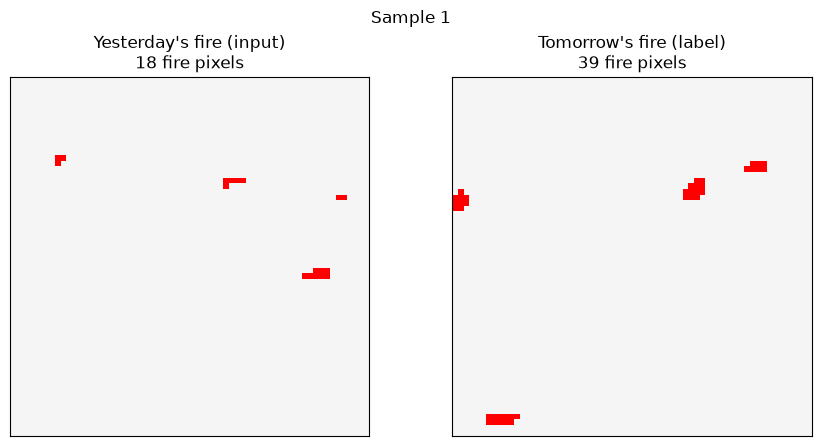

In [4]:
SAMPLE = 1

mask_colors = ListedColormap(["dimgray", "whitesmoke", "red"])
example = examples[SAMPLE]

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, name, title in zip(
    axes,
    ["PrevFireMask", "FireMask"],
    ["Yesterday's fire (input)", "Tomorrow's fire (label)"],
):
    ax.imshow(example[name], cmap=mask_colors, vmin=-1, vmax=1, interpolation="nearest")
    fire_pixels = int((example[name] == 1).sum())
    ax.set_title(f"{title}\n{fire_pixels} fire pixels")
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f"Sample {SAMPLE}")
plt.tight_layout()

## All inputs for one sample

Each panel is one input grid for the same patch, with its own color scale.

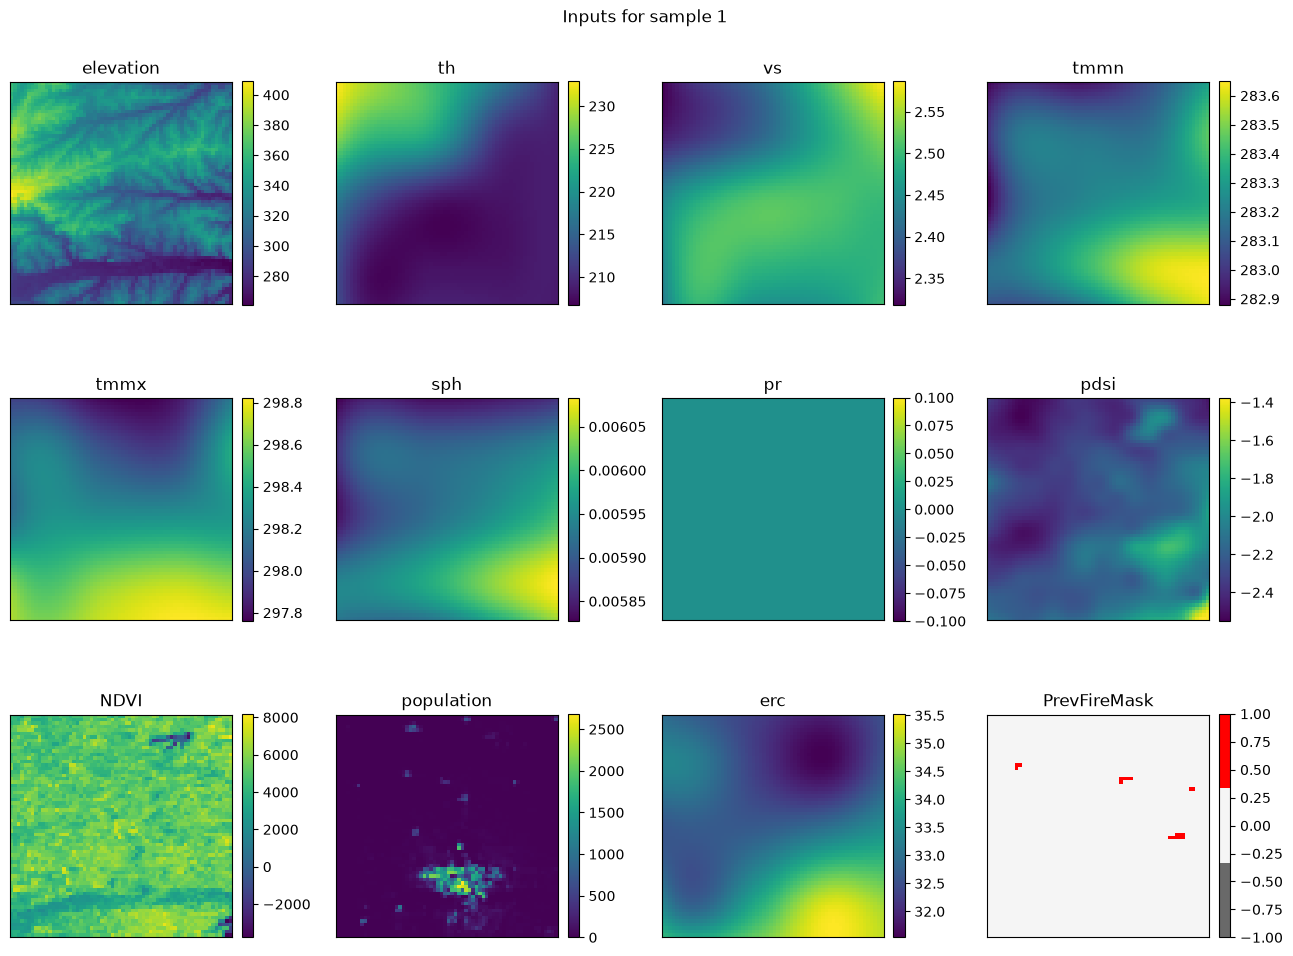

In [5]:
input_names = features.loc[features["role"] == "input", "feature"].tolist()

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax, name in zip(axes.flat, input_names):
    grid = example[name]
    if name == "PrevFireMask":
        image = ax.imshow(grid, cmap=mask_colors, vmin=-1, vmax=1, interpolation="nearest")
    else:
        image = ax.imshow(grid, cmap="viridis")
    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
for ax in axes.flat[len(input_names):]:
    ax.axis("off")
fig.suptitle(f"Inputs for sample {SAMPLE}")
plt.tight_layout()